# 01 - Datos, preprocesamiento y modelo baseline (TensorFlow/Keras)

**Propósito:** preparar MNIST, separar Train/Dev/Test, revisar las clases, normalizar píxeles y construir una línea base. Ejecutar todas las celdas de arriba hacia abajo en Google Colab.

**Configuración de la guía:** semilla 42; división estratificada 48.000 Train / 12.000 Dev / 10.000 Test; imágenes 28 × 28; normalización 0–255 a 0–1; Dense(128, ReLU) y Dense(10, softmax); Adam(0.001), batch size 64, 5 épocas.

## 1. Importaciones y reproducibilidad

In [ ]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
OUTPUT_DIR = Path("resultados")
OUTPUT_DIR.mkdir(exist_ok=True)
print("TensorFlow:", tf.__version__)
print("Semilla:", SEED)

TensorFlow: 2.21.0
Semilla: 42


## 2. Cargar MNIST, separar y normalizar datos
MNIST contiene imágenes de dígitos escritos a mano del 0 al 9. Test se conserva aparte para una evaluación final posterior; no se usa para escoger configuraciones.

In [ ]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.mnist.load_data()

x_train, x_dev, y_train, y_dev = train_test_split(
    x_train_full, y_train_full,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train_full
)

# Las imágenes se mantienen en escala de grises (28 x 28); solo se escala su intensidad.
x_train = x_train.astype("float32") / 255.0
x_dev   = x_dev.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

print("Train:", x_train.shape, y_train.shape)
print("Dev:", x_dev.shape, y_dev.shape)
print("Test:", x_test.shape, y_test.shape)
print("Rango de Train:", float(x_train.min()), float(x_train.max()))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Train: (48000, 28, 28) (48000,)
Dev: (12000, 28, 28) (12000,)
Test: (10000, 28, 28) (10000,)
Rango de Train: 0.0 1.0


## 3. Revisar distribución de las clases
La división estratificada debe conservar proporciones semejantes de los diez dígitos en Train y Dev. Las tablas permiten detectar distribuciones inesperadas.


TRAIN


,digito,cantidad,porcentaje
0,0,4738,9.87
1,1,5394,11.24
2,2,4766,9.93
3,3,4905,10.22
4,4,4674,9.74
5,5,4337,9.04
6,6,4734,9.86
7,7,5012,10.44
8,8,4681,9.75
9,9,4759,9.91



DEV


,digito,cantidad,porcentaje
0,0,1185,9.88
1,1,1348,11.23
2,2,1192,9.93
3,3,1226,10.22
4,4,1168,9.73
5,5,1084,9.03
6,6,1184,9.87
7,7,1253,10.44
8,8,1170,9.75
9,9,1190,9.92



TEST


,digito,cantidad,porcentaje
0,0,980,9.80
1,1,1135,11.35
2,2,1032,10.32
3,3,1010,10.10
4,4,982,9.82
5,5,892,8.92
6,6,958,9.58
7,7,1028,10.28
8,8,974,9.74
9,9,1009,10.09


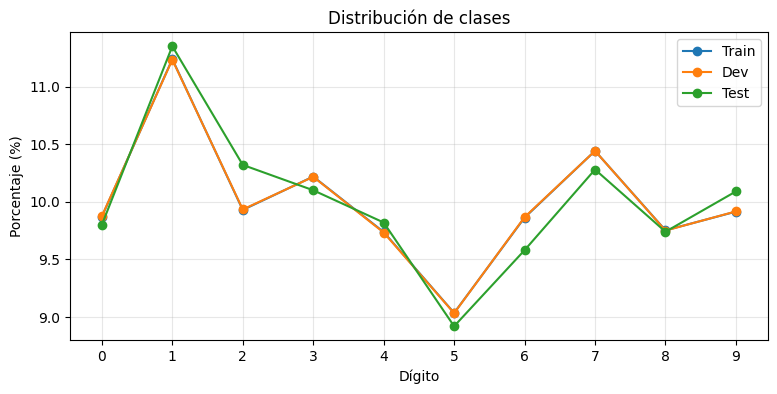

In [ ]:
def distribucion_clases(y, nombre):
    conteos = np.bincount(y, minlength=10)
    porcentajes = conteos / len(y) * 100
    tabla = pd.DataFrame({
        "digito": np.arange(10),
        "cantidad": conteos,
        "porcentaje": np.round(porcentajes, 2)
    })
    print(f"\n{nombre}")
    display(tabla)
    return tabla

dist_train = distribucion_clases(y_train, "TRAIN")
dist_dev = distribucion_clases(y_dev, "DEV")
dist_test = distribucion_clases(y_test, "TEST")

fig, ax = plt.subplots(figsize=(9, 4))
for nombre, y in [("Train", y_train), ("Dev", y_dev), ("Test", y_test)]:
    pct = np.bincount(y, minlength=10) / len(y) * 100
    ax.plot(np.arange(10), pct, marker="o", label=nombre)
ax.set_xticks(np.arange(10)); ax.set_xlabel("Dígito")
ax.set_ylabel("Porcentaje (%)"); ax.set_title("Distribución de clases")
ax.grid(True, alpha=.3); ax.legend(); plt.show()

**Qué analizar:** ¿están presentes los diez dígitos?, ¿los porcentajes son semejantes?, ¿hay alguna diferencia llamativa entre los conjuntos? Escribe una conclusión con los valores reales que arroje la tabla.

## 4. Inspeccionar algunas imágenes

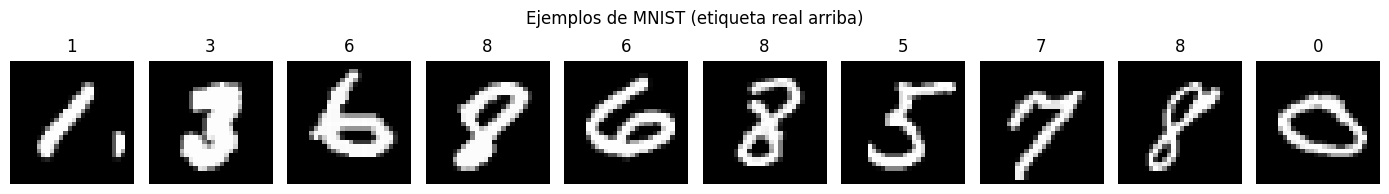

In [ ]:
fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for i, ax in enumerate(axes):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(str(y_train[i]))
    ax.axis("off")
plt.suptitle("Ejemplos de MNIST (etiqueta real arriba)")
plt.tight_layout(); plt.show()

## 5. Construir el modelo baseline

In [ ]:
def crear_modelo_baseline(units=128, optimizer=None):
    modelo = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(units, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])
    if optimizer is None:
        optimizer = keras.optimizers.Adam(learning_rate=0.001)
    modelo.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return modelo

keras.backend.clear_session()
tf.random.set_seed(SEED)
modelo_base = crear_modelo_baseline()
modelo_base.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Entrenar con validación explícita

In [ ]:
hist_base = modelo_base.fit(
    x_train, y_train,
    validation_data=(x_dev, y_dev),
    epochs=5,
    batch_size=64,
    verbose=1
)

loss_dev, acc_dev = modelo_base.evaluate(x_dev, y_dev, verbose=0)
print(f"Dev loss: {loss_dev:.4f}")
print(f"Dev accuracy: {acc_dev:.4f}")
modelo_base.save(OUTPUT_DIR / "modelo_baseline.keras")
pd.DataFrame(hist_base.history).to_csv(OUTPUT_DIR / "historial_baseline.csv", index=False)

Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9072 - loss: 0.3309 - val_accuracy: 0.9450 - val_loss: 0.1931
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9557 - loss: 0.1520 - val_accuracy: 0.9555 - val_loss: 0.1499
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.9693 - loss: 0.1072 - val_accuracy: 0.9613 - val_loss: 0.1314
Epoch 4/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9770 - loss: 0.0811 - val_accuracy: 0.9634 - val_loss: 0.1228
Epoch 5/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9821 - loss: 0.0635 - val_accuracy: 0.9653 - val_loss: 0.1183
Dev loss: 0.1183
Dev accuracy: 0.9653


## 7. Graficar Loss y Accuracy

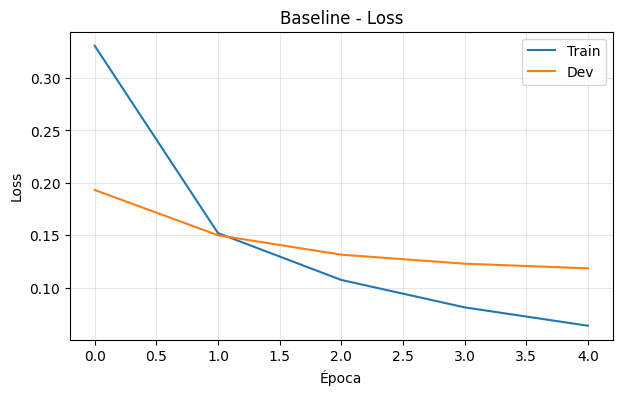

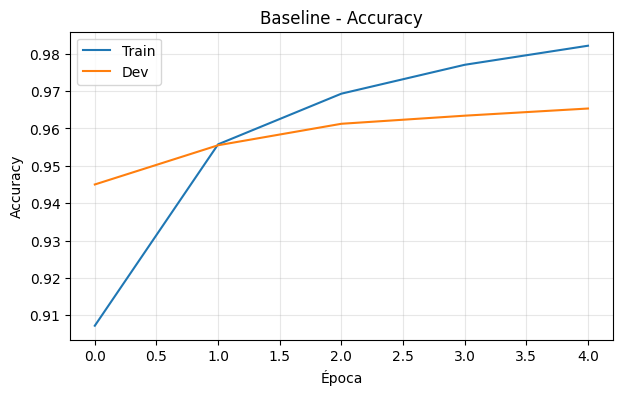

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(hist_base.history["loss"], label="Train")
ax.plot(hist_base.history["val_loss"], label="Dev")
ax.set_xlabel("Época"); ax.set_ylabel("Loss"); ax.set_title("Baseline - Loss")
ax.grid(True, alpha=.3); ax.legend(); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(hist_base.history["accuracy"], label="Train")
ax.plot(hist_base.history["val_accuracy"], label="Dev")
ax.set_xlabel("Época"); ax.set_ylabel("Accuracy"); ax.set_title("Baseline - Accuracy")
ax.grid(True, alpha=.3); ax.legend(); plt.show()

## 8. Análisis que debes escribir

- Reporta los tamaños de Train, Dev y Test.
- Explica por qué los píxeles se dividen entre 255.
- Describe si las curvas de pérdida bajan y la precisión sube.
- Compara Train frente a Dev: si Train mejora mientras Dev se estanca o empeora, puede existir overfitting.
- Registra el accuracy de Dev; **no uses Test para elegir hiperparámetros**.

**Resultado baseline:** Accuracy Dev = `{{copiar valor real}}`; Dev loss = `{{copiar valor real}}`. Sustituye estos campos tras ejecutar el notebook.